# 01 - Dataset preparation
**Objective.** Build a reproducible English text corpus with **>= 20 000 training** and **>= 2 000 test** sentences, strictly separated, and document it honestly.

**Concept.** The source encoder (Huffman) learns character statistics from *training* text only. If test sentences leaked into that training set the codebook would be tuned to them and the measured bits/character would be optimistic. We therefore split **by document** (a document never appears on both sides), then remove any sentence that is nevertheless identical in both sets.

**Source.** Brown Corpus from the NLTK data repository (`raw.githubusercontent.com/nltk/nltk_data`). If the download is impossible, place `brown.zip` in `data/raw/` (documented offline fallback).

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))          # project root = import root
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
FIG, TAB = ROOT / "results/figures", ROOT / "results/tables"
print("project root:", ROOT)

project root: /home/amardeep/Downloads/Project_Checkpoint_06/Exercise1


## 1. Build (or reuse) the dataset

In [2]:
import json
from task1_conventional.dataset import prepare_dataset, load_split
stats_file = ROOT / "data/processed/dataset_stats.json"
if not (ROOT / "data/train/train.txt").exists():
    stats = prepare_dataset(ROOT / "data")
else:
    stats = json.loads(stats_file.read_text())
display(pd.Series(stats, name="value").to_frame())

,value
source,https://raw.githubusercontent.com/nltk/nltk_da...
corpus,Brown Corpus (NLTK distribution)
seed,2024
n_documents,500
n_test_documents,75
raw_nonempty_lines,57340
n_sentences_after_filtering,30721
length_filter_chars,"[30, 120]"
n_train_sentences,25932
n_test_sentences,2000


In [3]:
train, test = load_split("train", ROOT / "data"), load_split("test", ROOT / "data")
assert len(train) >= 20000 and len(test) >= 2000, "assignment size requirement"
assert not set(train) & set(test), "train/test leakage"
print(f"train = {len(train)} sentences | test = {len(test)} sentences | exact overlap = {len(set(train) & set(test))}")
for s in test[:5]: print(" ", s)

train = 25932 sentences | test = 2000 sentences | exact overlap = 0
  "The statements may be highly prejudicial to my client", Bellows told the court.
  "Some of the defendants strongly indicated they knew they were receiving stolen property.
  It is impossible to get a fair trial when some of the defendants made statements involving themselves and others".
  "Yes, your honor", replied Bellows.
  He said evidence was obtained "in violation of the legal rights of citizens".


## 2. Preprocessing performed
1. POS tags removed, tokens **de-tokenised** (punctuation re-attached; quotes and contractions repaired). Capitalisation, digits and punctuation are **kept**.
2. Only sentences of **30-120 characters** with printable ASCII are kept (bounds the frame length, i.e. the number of resource blocks per sentence).
3. Exact duplicates removed; split by document; test = seeded random sample of 2 000 sentences from the held-out documents.

## 3. Character statistics

training character vocabulary size: 84 | test vocabulary: 78
characters in test but never in train: []


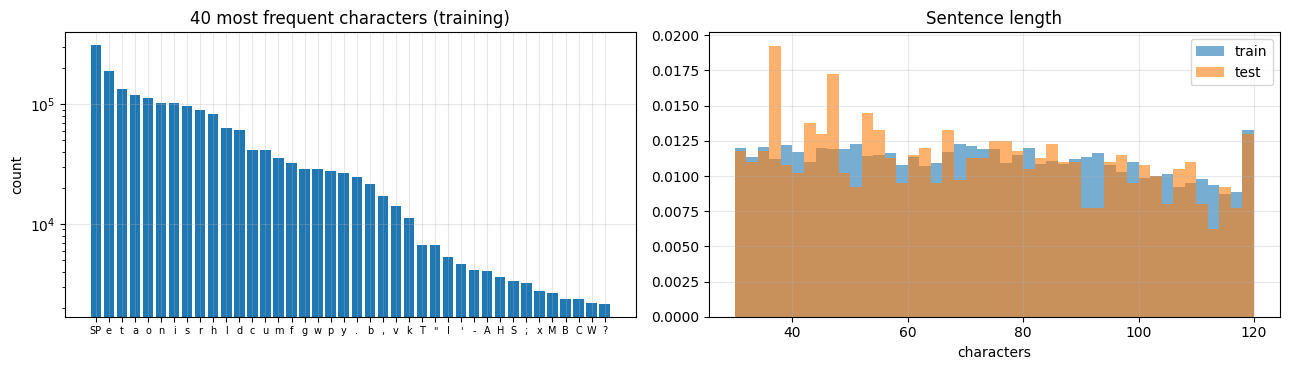

In [4]:
from collections import Counter
cnt = Counter("".join(train))
chars = sorted(cnt, key=cnt.get, reverse=True)
print("training character vocabulary size:", len(chars), "| test vocabulary:", len(set("".join(test))))
print("characters in test but never in train:", sorted(set("".join(test)) - set(chars)))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
top = chars[:40]
ax[0].bar(range(len(top)), [cnt[c] for c in top]); ax[0].set_xticks(range(len(top))); ax[0].set_xticklabels([repr(c)[1:-1] if c != " " else "SP" for c in top], fontsize=7)
ax[0].set_yscale("log"); ax[0].set_title("40 most frequent characters (training)"); ax[0].set_ylabel("count")
ax[1].hist([len(s) for s in train], bins=45, alpha=0.6, label="train", density=True)
ax[1].hist([len(s) for s in test], bins=45, alpha=0.6, label="test", density=True)
ax[1].set_title("Sentence length"); ax[1].set_xlabel("characters"); ax[1].legend()
fig.tight_layout(); fig.savefig(FIG / "dataset_overview.png", dpi=150); plt.show()

## 4. Limitations (please state them in the report)
* The Brown corpus is 1960s American English (news, fiction, academic prose): vocabulary and style differ from modern chat/web text.
* Character statistics are therefore specific to this corpus; the Huffman efficiency would change for other domains.
* Length filtering (30-120 chars) removes very short and very long sentences, so BLER values refer to *medium-length* sentences - longer sentences have higher BLER at the same SNR.
* Detokenisation is rule-based; a few artefacts (e.g. `Ill..`) remain.
* ASCII only, no accented characters.